<a href="https://colab.research.google.com/github/Thaer-F-Ali/CSVtoShp/blob/main/LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Create or load data
# Example: Predict pass/fail based on study hours
data = {
    'study_hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'pass_exam':   [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]  # 0 = fail, 1 = pass
}
df = pd.DataFrame(data)

X = df[['study_hours']]   # Features
y = df['pass_exam']       # Target

# Step 3: Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 4: Train logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # Probabilities for class 1

# Step 6: Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Step 7: Interpret coefficients
print("Coefficient (slope):", model.coef_[0][0])
print("Intercept:", model.intercept_[0])


Accuracy: 1.0
Confusion Matrix:
 [[1 0]
 [0 2]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Coefficient (slope): 1.0259594725716246
Intercept: -4.755575682392894


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


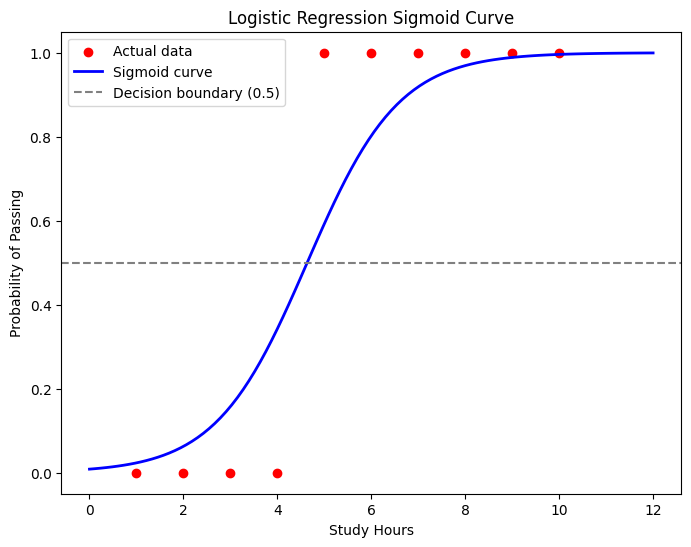

In [3]:
import matplotlib.pyplot as plt

# Step 8: Visualize the sigmoid curve
# Generate a range of study hours
X_range = np.linspace(0, 12, 100).reshape(-1, 1)
y_prob_range = model.predict_proba(X_range)[:, 1]

plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='red', label='Actual data')
plt.plot(X_range, y_prob_range, color='blue', linewidth=2, label='Sigmoid curve')
plt.axhline(0.5, color='gray', linestyle='--', label='Decision boundary (0.5)')
plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression Sigmoid Curve")
plt.legend()
plt.show()


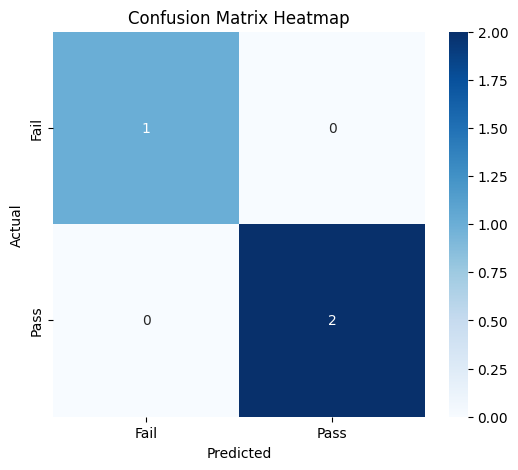

In [5]:
import seaborn as sns

# Step 9: Plot confusion matrix as heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()
